# Desafio Técnico - Cientista de Dados (Revi)
## As campanhas de WhatsApp geram venda incremental? Quanto, e em quais clientes?

Laércio Siqueira

---

### 0. Definição do problema

**Pergunta de negócio:** quanto de venda as campanhas de WhatsApp geram além do que os clientes comprariam de qualquer forma, e em quais clientes a mensagem rende mais?

Escolhi essa pergunta porque o lojista paga por mensagem e decide, a cada campanha, para quem enviar. O jeito mais simples de medir resultado (que vou chamar de "conta simples") é contar todo pedido feito até 7 dias depois da mensagem. O problema é que essa conta mistura duas coisas: venda causada pela campanha e venda de quem já ia comprar, e esses clientes costumam ser justamente os escolhidos para receber campanha. Sem separar as duas, não dá para saber se a campanha se paga. Na prática, a pergunta junta as direções 1 (propensão) e 2 (incrementalidade) do enunciado numa decisão: quem deve receber a próxima campanha.

**Métrica de sucesso:** receita incremental em 7 dias por 1.000 mensagens entregues, comparada ao custo dessas 1.000 mensagens. Como métrica secundária, olho os pedidos incrementais por 1.000 mensagens e quanto da conversão "atribuída" é de fato incremental. Em produção, isso deveria ser medido com um grupo de controle aleatório em cada campanha. Os dados não têm esse grupo, então boa parte do notebook é sobre como contornar isso e com que confiança.

Estrutura: 1) qualidade e limpeza dos dados; 2) exploração; 3) a conversão "atribuída" e por que ela engana; 4) efeito incremental usando as mensagens que falham como experimento natural; 5) fatores associados à conversão; 6) modelo baseline de propensão; 7) recomendações.

### Resumo

- As campanhas geram venda incremental nas lojas A e B. Os pedidos sobem nas 6 horas seguintes ao envio só para quem recebeu a mensagem; clientes com número inválido, que entram nos mesmos públicos, não mostram esse salto.
- Tamanho do efeito em 7 dias: na Loja A, cerca de 10 a 14 pedidos e R$ 1,0 a 2,2 mil a mais por 1.000 mensagens; na Loja B, 15 a 17 pedidos e R$ 2,0 a 4,9 mil. Na Loja C o resultado é inconclusivo.
- Só algo entre 35% e 90% da receita "atribuída" é incremental. Mesmo assim, a R$ 0,32 por mensagem, a campanha se paga com margem bruta acima de 6% a 31%, dependendo da loja e do método.
- Na Loja A, o efeito é maior em quem comprou há 31 a 90 dias e em contatos que nunca compraram. Para quem comprou há menos de 30 dias, o efeito é incerto.
- Para o mesmo cliente, mais mensagens no mês vêm acompanhadas de conversão menor por mensagem.
- O modelo de propensão tem lift de cerca de 3x no top 10% (teste em período posterior ao treino). Serve para ordenar clientes, mas propensão não é incrementalidade.
- Principal limitação: não há grupo de controle aleatório, então as estimativas devem ser lidas como um teto otimista. Primeira recomendação: holdout de 5 a 10% em toda campanha.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.inspection import permutation_importance

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
pd.set_option('display.max_colwidth', 120)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

DATA_DIR = Path('data')
if not (DATA_DIR / 'h_messages.csv').exists():
    DATA_DIR = Path('../data')
FIG_DIR = Path('figs'); FIG_DIR.mkdir(exist_ok=True)
RNG = np.random.default_rng(42)
D = 86400                 # segundos em um dia

# estilo dos gráficos (azul = recebeu a mensagem, cinza tracejado = grupo de comparação)
AZUL, CINZA, TINTA, TINTA2 = '#2a78d6', '#8a8984', '#0b0b0b', '#52514e'
mpl.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#b5b4ae',
    'axes.grid': True, 'grid.color': '#e7e6e2', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.labelcolor': TINTA2, 'xtick.color': TINTA2, 'ytick.color': TINTA2, 'text.color': TINTA,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'font.size': 9.5,
    'lines.linewidth': 2, 'legend.frameon': False,
})

### 1. Carga e qualidade dos dados

In [2]:
msg = pd.read_csv(DATA_DIR / 'h_messages.csv', index_col=0)
ped = pd.read_csv(DATA_DIR / 'h_orders.csv', index_col=0)
for c in ['created_at', 'replied_at', 'clicked_at']:
    msg[c] = pd.to_datetime(msg[c], format='mixed')
ped['ts'] = pd.to_datetime(ped['source_created_at'], format='mixed')

# os ids são hashes; troco por rótulos curtos só para facilitar a leitura
lojas = {c: f'Loja {chr(65 + i)}' for i, c in enumerate(msg.company_id.value_counts().index)}
msg['loja'] = msg.company_id.map(lojas)
ped['loja'] = ped.company_id.map(lojas)

print('mensagens:', msg.shape, '| pedidos:', ped.shape)
print('período mensagens:', msg.created_at.min().date(), 'a', msg.created_at.max().date())
print('período pedidos:  ', ped.ts.min().date(), 'a', ped.ts.max().date())
print('\nnulos (mensagens):'); print(msg.isna().sum()[lambda s: s > 0])
print('\nnulos (pedidos):'); print(ped.isna().sum()[lambda s: s > 0])

mensagens: (295394, 13) | pedidos: (123392, 10)
período mensagens: 2023-04-18 a 2024-07-19
período pedidos:   2018-12-12 a 2024-07-19

nulos (mensagens):
media_type     28173
replied_at    288024
clicked_at    274961
dtype: int64

nulos (pedidos):
status    34944
dtype: int64


In [3]:
# só 3 lojas e bem diferentes entre si, então a análise vai ser sempre por loja
perfil = pd.DataFrame({
    'mensagens': msg.groupby('loja').size(),
    'campanhas': msg.groupby('loja').whatsapp_campaign_id.nunique(),
    'templates': msg.groupby('loja').message_template_id.nunique(),
    'clientes contatados': msg.groupby('loja').customer_id.nunique(),
    '1ª mensagem': msg.groupby('loja').created_at.min().dt.date,
    'pedidos': ped.groupby('loja').size(),
    '1º pedido': ped.groupby('loja').ts.min().dt.date,
    'ticket mediano (R$)': ped.groupby('loja').value.median() / 100,
    '% pedidos sem status': ped.assign(x=ped.status.isna()).groupby('loja').x.mean() * 100,
    '% pedidos com cupom': ped.groupby('loja').has_coupon.mean() * 100,
})
perfil.style.format({'mensagens': '{:,.0f}', 'clientes contatados': '{:,.0f}', 'pedidos': '{:,.0f}', 'ticket mediano (R$)': 'R$ {:,.2f}',
                     '% pedidos sem status': '{:.0f}%', '% pedidos com cupom': '{:.0f}%'})

,mensagens,campanhas,templates,clientes contatados,1ª mensagem,pedidos,1º pedido,ticket mediano (R$),% pedidos sem status,% pedidos com cupom
loja,,,,,,,,,,
Loja A,"156,075",107,61,"54,082",2023-11-10,"63,314",2021-02-01,R$ 98.60,0%,69%
Loja B,"104,967",347,124,"15,905",2023-07-26,"25,134",2018-12-12,R$ 257.81,0%,52%
Loja C,"34,352",67,38,"5,410",2023-04-18,"34,944",2019-01-02,R$ 945.00,100%,0%


In [4]:
# anomalias encontradas
c = ped[ped.loja == 'Loja C']
hora_c = c.ts.dt.strftime('%H:%M').value_counts()
anom = pd.DataFrame([
    ('Pedidos', 'Loja C: 100% dos pedidos sem status', c.status.isna().sum()),
    ('Pedidos', 'Loja C: nenhum pedido com cupom', (~c.has_coupon).sum()),
    ('Pedidos', 'Loja C: horário sempre 23:59 (só a data é real)', hora_c.get('23:59', 0)),
    ('Pedidos', 'Valor negativo (todos na Loja C, parecem devoluções)', (ped.value < 0).sum()),
    ('Pedidos', 'Quantidade de itens <= 0', (ped.total_items_quantity <= 0).sum()),
    ('Pedidos', 'Valor zero', (ped.value == 0).sum()),
    ('Pedidos', 'Linhas duplicadas (tudo igual exceto id)', ped.drop(columns=['id']).duplicated().sum()),
    ('Pedidos', 'Status pending/expired/voided/refunded (lojas A e B)', ped.status.isin(['pending', 'expired', 'voided', 'refunded']).sum()),
    ('Mensagens', 'Clique registrado mas status "delivered" (leitura subnotificada)', ((msg.clicked_at.notna()) & (msg.status == 'delivered')).sum()),
    ('Mensagens', 'Status failed', (msg.status == 'failed').sum()),
    ('Mensagens', 'Status sent (aceita pelo WhatsApp, sem confirmação de entrega)', (msg.status == 'sent').sum()),
    ('Mensagens', 'Status enqueued/mismatch', msg.status.isin(['enqueued', 'mismatch']).sum()),
    ('Mensagens', 'Sem media_type (template só texto)', msg.media_type.isna().sum()),
    ('Mensagens', 'Campanhas com exatamente 5.000 mensagens (talvez limite da extração)', (msg.groupby('whatsapp_campaign_id').size() == 5000).sum()),
], columns=['base', 'achado', 'linhas'])
anom

,base,achado,linhas
0,Pedidos,Loja C: 100% dos pedidos sem status,34944
1,Pedidos,Loja C: nenhum pedido com cupom,34944
2,Pedidos,Loja C: horário sempre 23:59 (só a data é real),34944
3,Pedidos,"Valor negativo (todos na Loja C, parecem devoluções)",310
4,Pedidos,Quantidade de itens <= 0,3290
5,Pedidos,Valor zero,1857
6,Pedidos,Linhas duplicadas (tudo igual exceto id),66
7,Pedidos,Status pending/expired/voided/refunded (lojas A e B),8669
8,Mensagens,"Clique registrado mas status ""delivered"" (leitura subnotificada)",5460
9,Mensagens,Status failed,9708


In [5]:
# devoluções da Loja C: quantos negativos têm um pedido positivo de mesmo valor para o mesmo cliente
neg = ped[ped.value < 0]
pos = ped[ped.value > 0][['customer_id', 'value']].assign(value=lambda d: -d.value).drop_duplicates()
print(f"negativos com pedido positivo espelhado: {neg.merge(pos, on=['customer_id', 'value']).id.nunique() / len(neg):.0%}")

# cada campanha parece ser um disparo único (um template, uma mídia, poucos minutos)
camp = msg.groupby('whatsapp_campaign_id').agg(
    n=('id', 'size'), templates=('message_template_id', 'nunique'), midias=('media_type', lambda s: s.nunique(dropna=False)),
    duracao_min=('created_at', lambda s: (s.max() - s.min()).total_seconds() / 60))
print(f"campanhas com >1 template: {(camp.templates > 1).sum()} | com >1 mídia: {(camp.midias > 1).sum()} | "
      f"duração mediana do disparo: {camp.duracao_min.median():.1f} min (máx {camp.duracao_min.max():.0f} min)")
print('mensagens por campanha:', camp.n.describe(percentiles=[.5, .9]).round(0).to_dict())

negativos com pedido positivo espelhado: 75%
campanhas com >1 template: 0 | com >1 mídia: 0 | duração mediana do disparo: 0.5 min (máx 20 min)
mensagens por campanha: {'count': 521.0, 'mean': 567.0, 'std': 895.0, 'min': 1.0, '50%': 193.0, '90%': 1782.0, 'max': 5000.0}


#### Decisões de limpeza

| Decisão | Motivo |
|---|---|
| Pedido válido nas lojas A e B = `paid`, `partially_paid` ou `partially_refunded` | `pending` (cerca de 11% na Loja A) é boleto/Pix não pago; `expired`, `voided` e `refunded` não viraram receita. |
| Pedido válido na Loja C = valor > 0 e itens > 0, sem duplicatas | A Loja C não tem status nem cupom. Os valores negativos parecem devoluções (uns 3/4 espelham um pedido anterior), então não contam como compra. |
| Valores em centavos, convertidos para R$ | Ticket mediano de R$ 98,60 (A), R$ 257,81 (B) e R$ 945 (C) faz sentido; em reais seria absurdo. |
| Loja C usa janela em dias | Os pedidos da C só têm data (hora sempre 23:59). Para ela, "depois da mensagem" vale a partir do dia do envio. |
| Análise sempre separada por loja | São só 3 lojas, com ticket que varia 10 vezes e bases de tamanhos muito diferentes. Misturar daria paradoxo de Simpson. |
| `read` não é confiável | Cerca de 5,5 mil mensagens têm clique mas status `delivered`, porque o cliente pode desligar a confirmação de leitura. Junto `delivered` e `read` como "recebeu". |
| `sent`, `enqueued` e `mismatch` ficam fora das comparações | Não dá para saber se a mensagem chegou. |
| Duplicatas exatas removidas | 66 linhas iguais a outra (mesmo cliente, dia, valor e itens), todas da Loja C. |

In [6]:
VALIDOS = {'paid', 'partially_paid', 'partially_refunded'}
ped['valor'] = ped.value / 100
ped['dup'] = ped.drop(columns=['id']).duplicated()
eh_c = ped.loja == 'Loja C'
ped['valido'] = np.where(eh_c, (ped.value > 0) & (ped.total_items_quantity > 0) & ~ped.dup, ped.status.isin(VALIDOS))
msg['grupo'] = np.select([msg.status.isin(['delivered', 'read']), msg.status.eq('failed')], ['recebeu', 'falhou'], 'outro')
msg['media'] = msg.media_type.fillna('texto')
msg['clicou'] = msg.clicked_at.notna()
msg['respondeu'] = msg.replied_at.notna()

# chave numérica de cliente (o mesmo customer_id nunca aparece em duas lojas)
chaves = pd.Index(pd.concat([msg.customer_id, ped.customer_id]).unique())
msg['ck'] = chaves.get_indexer(msg.customer_id).astype('int64')
ped['ck'] = chaves.get_indexer(ped.customer_id).astype('int64')
print(ped.groupby('loja').valido.mean().rename('% pedidos válidos').map('{:.1%}'.format))


def epoch(s):
    return s.astype('datetime64[s]').astype('int64').to_numpy()


class IndicePedidos:
    """Conta os pedidos válidos (e soma a receita) de cada cliente numa janela (t0, t1].
    Junta cliente e horário numa chave só (cliente*1e10 + epoch) e usa busca binária,
    o que evita fazer merge de milhões de linhas."""
    K = 10**10

    def __init__(self, pedidos):
        v = pedidos[pedidos.valido]
        k = v.ck.to_numpy() * self.K + epoch(v.ts)
        ordem = np.argsort(k)
        self.k = k[ordem]
        self.acum = np.concatenate([[0.0], v.valor.to_numpy()[ordem].cumsum()])

    def janela(self, ck, t0, t1):
        a = np.searchsorted(self.k, ck * self.K + t0, 'right')
        b = np.searchsorted(self.k, ck * self.K + t1, 'right')
        return b - a, self.acum[b] - self.acum[a]

    def ultimo_antes(self, ck, t):
        b = np.searchsorted(self.k, ck * self.K + t, 'left') - 1
        ok = (b >= 0) & (self.k[np.maximum(b, 0)] >= ck * self.K)
        return np.where(ok, self.k[np.maximum(b, 0)] - ck * self.K, np.nan)

    def primeiro(self, ck):
        a = np.minimum(np.searchsorted(self.k, ck * self.K, 'left'), len(self.k) - 1)
        ok = self.k[a] < (ck + 1) * self.K
        return np.where(ok, self.k[a] - ck * self.K, np.nan)


idx = IndicePedidos(ped)
# referência de cada mensagem: horário do envio (A e B) ou começo do dia do envio (C, que só tem data)
msg['t0'] = np.where(msg.loja == 'Loja C', epoch(msg.created_at.dt.normalize()), epoch(msg.created_at))
FIM = ped.ts.max()
print('fim da base de pedidos:', FIM)

loja
Loja A    88.8%
Loja B    93.7%
Loja C    90.0%
Name: % pedidos válidos, dtype: str
fim da base de pedidos: 2024-07-19 13:09:34


### 2. Exploração

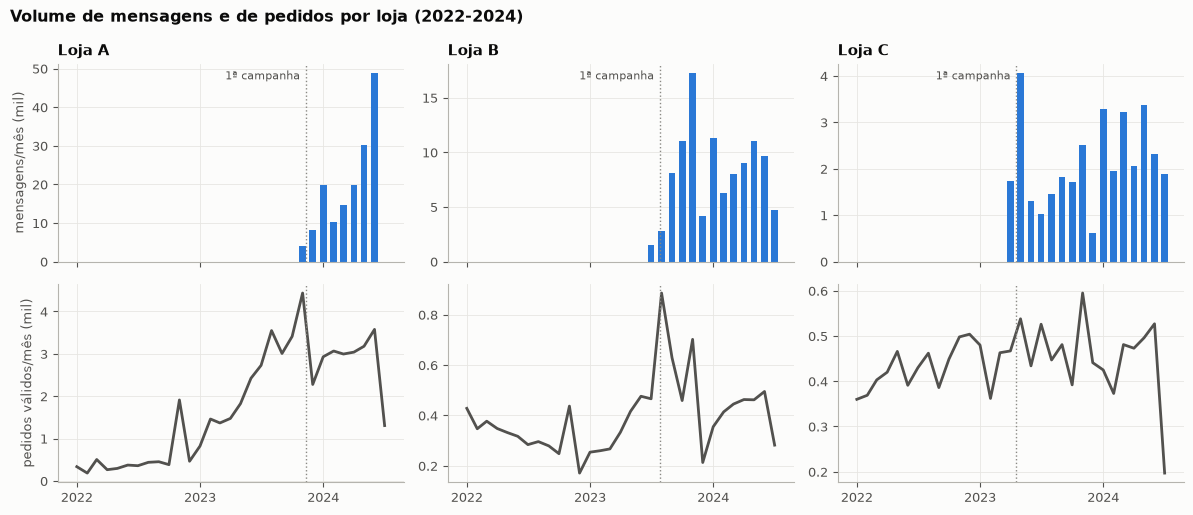

In [7]:
mes_m = msg.groupby([msg.created_at.dt.to_period('M'), 'loja']).size().unstack()
mes_p = ped[ped.valido].groupby([ped.ts.dt.to_period('M'), 'loja']).size().unstack()
inicio = pd.Period('2022-01', 'M')
fig, ax = plt.subplots(2, 3, figsize=(12, 5.2), sharex=True)
for j, lj in enumerate(['Loja A', 'Loja B', 'Loja C']):
    s1 = mes_m[lj].reindex(pd.period_range(inicio, '2024-07', freq='M'))
    s2 = mes_p[lj].reindex(pd.period_range(inicio, '2024-07', freq='M'))
    x = s1.index.to_timestamp()
    ax[0, j].bar(x, s1.fillna(0) / 1000, width=20, color=AZUL)
    ax[1, j].plot(x, s2 / 1000, color=TINTA2)
    ax[0, j].set_title(lj)
    primeira = msg[msg.loja == lj].created_at.min()
    for a in ax[:, j]:
        a.axvline(primeira, color=CINZA, ls=':', lw=1)
    ax[0, j].annotate('1ª campanha', (primeira, ax[0, j].get_ylim()[1] * 0.92), fontsize=8, color=TINTA2, xytext=(-4, 0),
                      textcoords='offset points', ha='right')
    ax[1, j].xaxis.set_major_locator(mpl.dates.YearLocator())
    ax[1, j].xaxis.set_major_formatter(mpl.dates.DateFormatter('%Y'))
ax[0, 0].set_ylabel('mensagens/mês (mil)')
ax[1, 0].set_ylabel('pedidos válidos/mês (mil)')
fig.suptitle('Volume de mensagens e de pedidos por loja (2022-2024)', x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
fig.savefig(FIG_DIR / 'fig1_volumes.png', dpi=160)

A Loja A saiu de uns 400 para 3 a 5 mil pedidos por mês ao longo de 2023, antes da primeira campanha (nov/2023). Uma comparação "antes e depois do WhatsApp" daria esse crescimento todo para as campanhas. É o primeiro motivo para precisar de um grupo de comparação.

In [8]:
funil = msg.groupby('loja').agg(
    mensagens=('id', 'size'),
    falhou=('status', lambda s: (s == 'failed').mean()),
    nao_confirmada=('status', lambda s: s.isin(['sent', 'enqueued', 'mismatch']).mean()),
    recebeu=('grupo', lambda s: (s == 'recebeu').mean()),
    status_read=('status', lambda s: (s == 'read').mean()),
    clicou=('clicou', 'mean'), respondeu=('respondeu', 'mean'))
funil.columns = ['mensagens', 'falhou', 'sem confirmação (sent/enqueued/mismatch)', 'recebeu (delivered+read)', 'status read', 'clicou', 'respondeu']
funil.style.format({'mensagens': '{:,.0f}', **{c: '{:.1%}' for c in funil.columns[1:]}})

,mensagens,falhou,sem confirmação (sent/enqueued/mismatch),recebeu (delivered+read),status read,clicou,respondeu
loja,,,,,,,
Loja A,"156,075",3.1%,2.8%,94.0%,58.0%,8.3%,1.5%
Loja B,"104,967",3.8%,5.9%,90.3%,42.3%,3.5%,1.7%
Loja C,"34,352",2.4%,5.1%,92.4%,60.2%,11.1%,9.4%


In [9]:
# a falha parece ser do cliente (número inválido / sem WhatsApp) e não da campanha
m_ord = msg.sort_values(['ck', 'created_at'])
m_ord['falhou'] = m_ord.status.eq('failed')
m_ord['falhou_antes'] = m_ord.groupby('ck').falhou.shift()
persist = m_ord.dropna(subset=['falhou_antes']).groupby(['loja', 'falhou_antes']).falhou.mean().unstack()
persist.columns = ['P(falha | anterior entregue)', 'P(falha | anterior falhou)']
por_cliente = m_ord.groupby('ck').agg(n=('id', 'size'), nf=('falhou', 'sum'))
com_falha = por_cliente[por_cliente.nf > 0]
print(f'clientes com alguma falha: {len(com_falha):,} | desses, falharam em TODAS as mensagens: {(com_falha.nf == com_falha.n).mean():.0%}')
taxa_camp = msg.groupby('whatsapp_campaign_id').status.apply(lambda s: (s == 'failed').mean())
print(f'taxa de falha por campanha: mediana {taxa_camp.median():.1%}, p90 {taxa_camp.quantile(.9):.1%}')
persist.style.format('{:.1%}')

clientes com alguma falha: 6,228 | desses, falharam em TODAS as mensagens: 82%
taxa de falha por campanha: mediana 2.1%, p90 7.1%


,P(falha | anterior entregue),P(falha | anterior falhou)
loja,,
Loja A,0.5%,94.9%
Loja B,0.5%,92.6%
Loja C,0.5%,86.9%


Esse é o ponto central da análise: quem falha uma vez falha de novo em cerca de 90% das vezes. Esses clientes entram nas mesmas regras de público dos outros, mas nunca recebem nada, o que faz deles um grupo de comparação natural. Não é perfeito (ver 4.5), mas é bem melhor do que comparar quem leu com quem não leu.

### 3. A conversão "atribuída" e por que ela engana

Conversão em 7 dias = o cliente fez um pedido válido nos 7 dias seguintes ao envio (na Loja C, do dia do envio até 7 dias depois).

In [10]:
ck_m, t0_m = msg.ck.to_numpy(), msg.t0.to_numpy()
for nome, a, b in [('conv7', 0, 7), ('pre7', -7, 0), ('pre28', -28, 0)]:
    n, r = idx.janela(ck_m, t0_m + a * D, t0_m + b * D)
    msg[nome] = n > 0
    msg[nome + '_r'] = r
cens = msg.created_at <= FIM - pd.Timedelta(days=7)   # só mensagens com os 7 dias completos de acompanhamento
tab = (msg[cens].groupby(['loja', 'status'])
       .agg(mensagens=('id', 'size'), conv7=('conv7', 'mean'), comprou_7d_antes=('pre7', 'mean'), comprou_28d_antes=('pre28', 'mean'))
       .query('mensagens >= 300'))
tab.style.format({'mensagens': '{:,.0f}', 'conv7': '{:.2%}', 'comprou_7d_antes': '{:.2%}', 'comprou_28d_antes': '{:.2%}'})

In [11]:
rec = msg[cens & (msg.grupo == 'recebeu')]
atrib = rec.groupby('loja').agg(msgs=('id', 'size'), conv7=('conv7', 'mean'), receita_7d=('conv7_r', 'sum'))
receita_loja = {lj: ped[ped.valido & (ped.loja == lj) & (ped.ts >= msg[msg.loja == lj].created_at.min())].valor.sum() for lj in atrib.index}
atrib['% receita da loja no período'] = atrib.receita_7d / pd.Series(receita_loja)
atrib['receita "atribuída" por 1.000 msgs (R$)'] = atrib.receita_7d / atrib.msgs * 1000
atrib.style.format({'msgs': '{:,.0f}', 'conv7': '{:.2%}', 'receita_7d': 'R$ {:,.0f}', '% receita da loja no período': '{:.0%}',
                    'receita "atribuída" por 1.000 msgs (R$)': 'R$ {:,.0f}'})

,msgs,conv7,receita_7d,% receita da loja no período,"receita ""atribuída"" por 1.000 msgs (R$)"
loja,,,,,
Loja A,"146,715",2.18%,"R$ 403,614",13%,"R$ 2,751"
Loja B,"90,969",1.90%,"R$ 519,704",33%,"R$ 5,713"
Loja C,"30,969",2.84%,"R$ 1,573,354",14%,"R$ 50,804"


Pela conta simples, quem recebe converte de 2 a 6 vezes mais do que quem teve a mensagem falha. Mas essa conta dá para a campanha todo pedido feito na janela, inclusive de quem já ia comprar. Dois sinais de que ela exagera:

1. Quem leu já comprava mais antes da mensagem (coluna `comprou_28d_antes`). Quem lê é um cliente diferente de quem não lê, então "leu vs. não leu" não mede efeito.
2. Os públicos parecem escolhidos por compra recente: de 6% a 9% compraram nos 28 dias anteriores nas lojas A e C. É exatamente quem tem mais chance de comprar de novo sem estímulo nenhum.

A pergunta que importa é o que teria acontecido com esses mesmos clientes sem a mensagem.

### 4. Quanto é incremental?

Como não existe grupo de controle aleatório, usei duas abordagens, as duas baseadas nos clientes cujas mensagens falham:

- 4.1 Linha do tempo dos pedidos em volta do envio (todas as mensagens, lojas A e B). Se a mensagem causa compra, os pedidos devem subir logo depois do envio e só para quem recebeu.
- 4.2 Primeiro contato com pareamento. Comparo clientes cuja primeira mensagem chegou com clientes cuja primeira mensagem falhou, pareados por loja, mês, recência e frequência de compra. Olhar só o primeiro contato evita que o "antes" de quem recebe já esteja inflado por campanhas anteriores.

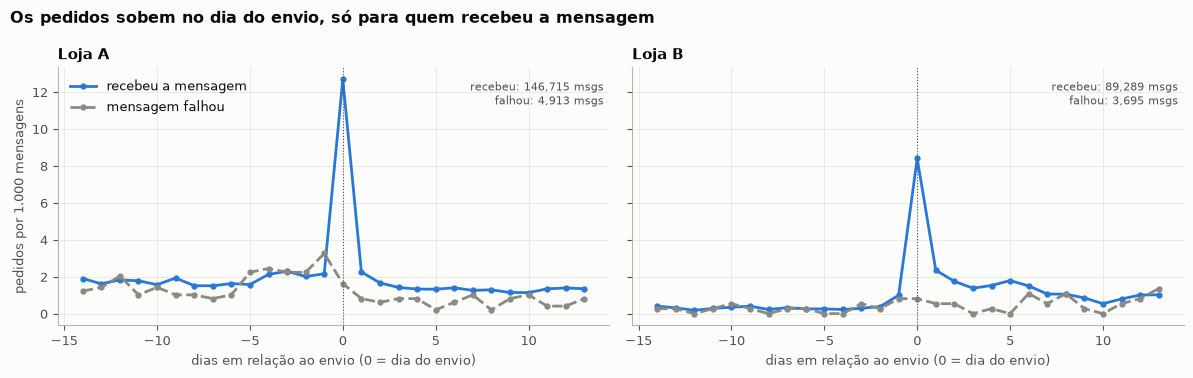

In [12]:
# 4.1: pedidos por 1.000 mensagens em cada dia em volta do envio (lojas A e B, que têm horário)
base41 = msg[(msg.grupo != 'outro') & (msg.loja != 'Loja C') & (msg.created_at >= '2023-08-01')
             & (msg.created_at <= FIM - pd.Timedelta(days=14))].copy()
ck41, t41 = base41.ck.to_numpy(), base41.t0.to_numpy()
linhas = []
for dia in range(-14, 14):
    n, _ = idx.janela(ck41, t41 + dia * D, t41 + (dia + 1) * D)
    linhas.append(pd.DataFrame({'dia': dia, 'loja': base41.loja.values, 'grupo': base41.grupo.values, 'n': n}))
diario = pd.concat(linhas).groupby(['loja', 'grupo', 'dia']).n.mean().mul(1000).unstack(['loja', 'grupo'])

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for a, lj in zip(ax, ['Loja A', 'Loja B']):
    a.plot(diario.index, diario[(lj, 'recebeu')], color=AZUL, marker='o', ms=3.5, label='recebeu a mensagem')
    a.plot(diario.index, diario[(lj, 'falhou')], color=CINZA, ls='--', marker='o', ms=3.5, label='mensagem falhou')
    a.axvline(0, color=TINTA2, lw=0.8, ls=':')
    a.set_title(lj)
    a.set_xlabel('dias em relação ao envio (0 = dia do envio)')
    n_r, n_f = (base41.loja == lj).mul(base41.grupo == 'recebeu').sum(), (base41.loja == lj).mul(base41.grupo == 'falhou').sum()
    a.text(0.99, 0.95, f'recebeu: {n_r:,} msgs\nfalhou: {n_f:,} msgs', transform=a.transAxes, ha='right', va='top', fontsize=8, color=TINTA2)
ax[0].set_ylabel('pedidos por 1.000 mensagens')
ax[0].legend(loc='upper left')
fig.suptitle('Os pedidos sobem no dia do envio, só para quem recebeu a mensagem', x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
fig.savefig(FIG_DIR / 'fig2_linha_do_tempo.png', dpi=160)

In [13]:
# zoom em blocos de 6h (o clique mediano acontece uns 47 min depois do envio)
linhas = []
for h in range(-24, 48, 6):
    n, _ = idx.janela(ck41, t41 + h * 3600, t41 + (h + 6) * 3600)
    linhas.append(pd.DataFrame({'bloco': f'{h:+d}h a {h + 6:+d}h', 'h': h, 'grupo': base41.grupo.values, 'n': n}))
horas = pd.concat(linhas).groupby(['h', 'bloco', 'grupo']).n.mean().mul(1000).unstack('grupo').droplevel('h')
print('atraso mediano entre envio e clique (min):', round(((msg.clicked_at - msg.created_at).dt.total_seconds() / 60).median(), 1))
horas.style.format('{:.2f}').set_caption('pedidos por 1.000 mensagens, blocos de 6 horas (A+B)')

atraso mediano entre envio e clique (min): 47.1


grupo,falhou,recebeu
bloco,,
-24h a -18h,0.46,0.37
-18h a -12h,0.23,0.25
-12h a -6h,0.35,0.40
-6h a +0h,1.16,0.70
+0h a +6h,0.35,8.19
+6h a +12h,0.35,1.17
+12h a +18h,0.12,0.71
+18h a +24h,0.46,1.00
+24h a +30h,0.23,0.91


In [14]:
# quantificando: semana do envio (dias 0 a 6) contra a linha de base da mesma mensagem (dias -14 a -8)
n_post, r_post = idx.janela(ck41, t41, t41 + 7 * D)
n_pre, r_pre = idx.janela(ck41, t41 - 14 * D, t41 - 7 * D)
base41 = base41.assign(n_post=n_post, n_pre=n_pre, r_post=r_post, r_pre=r_pre)


def boot_cliente(df, f, B=500):
    """Bootstrap sorteando clientes, porque as mensagens de um mesmo cliente não são independentes."""
    grupos = {g: d for g, d in df.groupby('grupo')}
    agg = {g: d.groupby('ck')[['n_post', 'n_pre', 'r_post', 'r_pre']].sum().assign(m=d.groupby('ck').size()) for g, d in grupos.items()}
    est = []
    for _ in range(B):
        amostra = {g: a.iloc[RNG.integers(0, len(a), len(a))] for g, a in agg.items()}
        est.append(f(amostra))
    return np.percentile(est, [2.5, 97.5], axis=0)


def efeitos(a):
    r, c = a['recebeu'], a['falhou']
    por = lambda d, col: d[col].sum() / d.m.sum() * 1000
    exc_ped = por(r, 'n_post') - por(r, 'n_pre')
    did_ped = exc_ped - (por(c, 'n_post') - por(c, 'n_pre'))
    exc_rec = por(r, 'r_post') - por(r, 'r_pre')
    did_rec = exc_rec - (por(c, 'r_post') - por(c, 'r_pre'))
    return np.array([exc_ped, did_ped, exc_rec, did_rec])


ROT41 = ['pedidos extras / 1.000 msgs (vs. linha de base)', 'pedidos extras / 1.000 msgs (dif-em-dif)',
         'receita extra / 1.000 msgs, R$ (vs. linha de base)', 'receita extra / 1.000 msgs, R$ (dif-em-dif)']
res41 = []
for lj in ['Loja A', 'Loja B']:
    d = base41[base41.loja == lj]
    agg_full = {g: x.groupby('ck')[['n_post', 'n_pre', 'r_post', 'r_pre']].sum().assign(m=x.groupby('ck').size()) for g, x in d.groupby('grupo')}
    pt = efeitos(agg_full)
    lo, hi = boot_cliente(d, efeitos)
    for i, nome in enumerate(ROT41):
        res41.append((lj, nome, pt[i], lo[i], hi[i]))
    rr = d[d.grupo == 'recebeu']
    res41.append((lj, 'referência: pedidos atribuídos / 1.000 msgs (tudo em 7 dias)', rr.n_post.sum() / len(rr) * 1000, np.nan, np.nan))
    res41.append((lj, 'referência: receita atribuída / 1.000 msgs, R$', rr.r_post.sum() / len(rr) * 1000, np.nan, np.nan))
res41 = pd.DataFrame(res41, columns=['loja', 'estimativa (7 dias)', 'valor', 'IC95 inf', 'IC95 sup'])
res41.style.format({'valor': '{:,.1f}', 'IC95 inf': '{:,.1f}', 'IC95 sup': '{:,.1f}'}, na_rep='').hide(axis='index')

loja,estimativa (7 dias),valor,IC95 inf,IC95 sup
Loja A,pedidos extras / 1.000 msgs (vs. linha de base),9.9,9.0,10.9
Loja A,pedidos extras / 1.000 msgs (dif-em-dif),13.6,10.3,17.0
Loja A,"receita extra / 1.000 msgs, R$ (vs. linha de base)","1,031.3",889.4,"1,183.3"
Loja A,"receita extra / 1.000 msgs, R$ (dif-em-dif)","1,945.0","1,366.4","2,649.8"
Loja A,referência: pedidos atribuídos / 1.000 msgs (tudo em 7 dias),22.1,,
Loja A,"referência: receita atribuída / 1.000 msgs, R$","2,751.0",,
Loja B,pedidos extras / 1.000 msgs (vs. linha de base),16.5,15.3,18.1
Loja B,pedidos extras / 1.000 msgs (dif-em-dif),14.9,12.1,17.8
Loja B,"receita extra / 1.000 msgs, R$ (vs. linha de base)","4,929.4","4,492.0","5,428.0"
Loja B,"receita extra / 1.000 msgs, R$ (dif-em-dif)","4,533.7","3,767.4","5,252.6"


Usei dois estimadores, cada um com um ponto fraco:

- vs. linha de base: compara a semana do envio com os dias -14 a -8 das mesmas mensagens. Não depende do grupo "falhou" e tende a ser conservador, porque os públicos são escolhidos logo depois de compras e, sem a mensagem, as compras cairiam abaixo dessa linha de base (é o que acontece no grupo "falhou").
- diferença-em-diferenças: desconta essa queda usando o grupo "falhou". É mais completo, mas herda o ruído e a possível seleção desse grupo pequeno.

Na Loja A, 1.000 mensagens entregues geram de 10 a 14 pedidos a mais na semana do envio (R$ 1,0 a 1,9 mil); na Loja B, de 15 a 17 pedidos (R$ 4,5 a 4,9 mil). O salto se concentra nas primeiras 6 horas (8,2 pedidos por 1.000 mensagens, contra uns 0,4 num bloco normal de 6 horas), e o grupo "falhou" não sobe nada. Se o pico fosse efeito de promoção no site ou sazonalidade, apareceria nos dois grupos.

#### 4.2 Primeiro contato com pareamento

Para cada cliente, pego a primeira mensagem que ele recebeu da loja. Tratado: essa mensagem chegou. Controle: falhou (e, pela persistência, as seguintes quase sempre falham também). Pareio por estratos de loja x mês do primeiro contato x recência x número de pedidos nos 365 dias anteriores, e calculo o efeito médio nos tratados (ATT): a diferença dentro de cada estrato, ponderada pelo número de tratados.

Como checagem, uso placebos: as janelas de 90-120 e 60-90 dias antes do contato não podem ter sido afetadas pela mensagem. Se os grupos pareados forem diferentes ali, o pareamento não está dando conta.

In [15]:
prim = msg.sort_values('created_at').groupby('ck').head(1)
prim = prim[prim.grupo != 'outro'].copy()
ck_p, t0_p = prim.ck.to_numpy(), prim.t0.to_numpy()
ult = idx.ultimo_antes(ck_p, t0_p)
prim['recencia'] = np.where(np.isnan(ult), np.inf, (t0_p - ult) / D)
prim['n365'], _ = idx.janela(ck_p, t0_p - 365 * D, t0_p)
JANELAS = {'pre120_90': (-120, -90), 'pre90_60': (-90, -60), 'pre60_30': (-60, -30), 'pre30_0': (-30, 0),
           'pos0_7': (0, 7), 'pos0_30': (0, 30), 'pos30_60': (30, 60), 'pos60_90': (60, 90), 'pos0_90': (0, 90)}
for nome, (a, b) in JANELAS.items():
    n, r = idx.janela(ck_p, t0_p + a * D, t0_p + b * D)
    prim[nome] = (n > 0).astype(float)
    prim[nome + '_r'] = r
    prim[nome + '_n'] = n
prim['T'] = (prim.grupo == 'recebeu').astype(int)
prim['seg_rec'] = pd.cut(prim.recencia, [-1, 30, 90, 180, 365, 1e6, np.inf], labels=['0-30d', '31-90d', '91-180d', '181-365d', '>365d', 'nunca comprou'])
prim['seg_freq'] = pd.cut(prim.n365, [-1, 0, 1, 2, 4, 1e9], labels=['0', '1', '2', '3-4', '5+'])
prim['mes'] = prim.created_at.dt.to_period('M').astype(str)
prim['estrato'] = pd.factorize(prim.loja + '|' + prim.mes + '|' + prim.seg_rec.astype(str) + '|' + prim.seg_freq.astype(str))[0]
prim['seguimento_dias'] = (FIM - prim.created_at).dt.days
print(prim.groupby(['loja', 'grupo']).size().unstack().rename_axis(None, axis=1))


def att(estrato, T, y):
    nc = estrato.max() + 1
    n1 = np.bincount(estrato, weights=T, minlength=nc); n0 = np.bincount(estrato, weights=1 - T, minlength=nc)
    s1 = np.bincount(estrato, weights=T * y, minlength=nc); s0 = np.bincount(estrato, weights=(1 - T) * y, minlength=nc)
    ok = (n1 > 0) & (n0 > 0)
    m1, m0, w = s1[ok] / n1[ok], s0[ok] / n0[ok], n1[ok]
    return (w * m1).sum() / w.sum(), (w * m0).sum() / w.sum(), (w * (m1 - m0)).sum() / w.sum(), w.sum() / T.sum()


def att_ic(df, y, B=400):
    e, T, v = df.estrato.to_numpy(), df['T'].to_numpy().astype(float), df[y].to_numpy().astype(float)
    m1, m0, ef, cob = att(e, T, v)
    i1, i0 = np.where(T == 1)[0], np.where(T == 0)[0]
    boots = []
    for _ in range(B):
        s = np.concatenate([RNG.choice(i1, len(i1)), RNG.choice(i0, len(i0))])
        boots.append(att(e[s], T[s], v[s])[2])
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return m1, m0, ef, lo, hi, cob


def janela_ok(df, y):
    """Para os desfechos depois do contato, mantém só quem tem a janela inteira de acompanhamento."""
    fim = JANELAS[y.replace('_r', '')][1]
    return df[df.seguimento_dias >= max(fim, 0)]


saida = []
for lj in ['Loja A', 'Loja B', 'Loja C']:
    d = prim[prim.loja == lj]
    for y, rotulo in [('pre120_90', 'placebo: comprou 90-120 dias ANTES'), ('pre90_60', 'placebo: comprou 60-90 dias ANTES'),
                      ('pos0_7', 'comprou em 7 dias'), ('pos0_30', 'comprou em 30 dias'), ('pos0_90', 'comprou em 90 dias'),
                      ('pos0_7_r', 'receita por cliente em 7 dias (R$)'), ('pos0_30_r', 'receita por cliente em 30 dias (R$)'),
                      ('pos0_90_r', 'receita por cliente em 90 dias (R$)')]:
        dd = janela_ok(d, y)
        m1, m0, ef, lo, hi, cob = att_ic(dd, y)
        saida.append((lj, rotulo, m1, m0, ef, lo, hi, int(dd['T'].sum()), int((1 - dd['T']).sum())))
res42 = pd.DataFrame(saida, columns=['loja', 'desfecho', 'recebeu', 'falhou (pareado)', 'efeito', 'IC95 inf', 'IC95 sup', 'n recebeu', 'n falhou'])


def estilo42(df):
    out = df.copy()
    for c in ['recebeu', 'falhou (pareado)', 'efeito', 'IC95 inf', 'IC95 sup']:
        out[c] = [f'R$ {v:,.2f}' if 'R$' in d else f'{v:+.2%}' if c in ('efeito', 'IC95 inf', 'IC95 sup') else f'{v:.2%}' for v, d in zip(df[c], df.desfecho)]
    return out.style.hide(axis='index')


estilo42(res42)

        falhou  recebeu
loja                   
Loja A    3262    50652
Loja B    1730    13958
Loja C     227     5066


loja,desfecho,recebeu,falhou (pareado),efeito,IC95 inf,IC95 sup,n recebeu,n falhou
Loja A,placebo: comprou 90-120 dias ANTES,7.92%,8.27%,-0.35%,-1.09%,+0.75%,50652,3262
Loja A,placebo: comprou 60-90 dias ANTES,9.08%,10.08%,-1.00%,-2.04%,-0.11%,50652,3262
Loja A,comprou em 7 dias,2.17%,0.39%,+1.78%,+1.42%,+2.05%,50652,3262
Loja A,comprou em 30 dias,4.69%,1.86%,+2.83%,+2.00%,+3.45%,40945,2354
Loja A,comprou em 90 dias,10.34%,4.65%,+5.69%,+4.09%,+6.93%,28042,1415
Loja A,receita por cliente em 7 dias (R$),R$ 2.59,R$ 0.41,R$ 2.18,R$ 1.80,R$ 2.45,50652,3262
Loja A,receita por cliente em 30 dias (R$),R$ 5.95,R$ 2.49,R$ 3.46,R$ 1.61,R$ 4.51,40945,2354
Loja A,receita por cliente em 90 dias (R$),R$ 14.31,R$ 6.40,R$ 7.91,R$ 5.14,R$ 9.72,28042,1415
Loja B,placebo: comprou 90-120 dias ANTES,2.81%,2.22%,+0.58%,-0.38%,+1.40%,13958,1730
Loja B,placebo: comprou 60-90 dias ANTES,4.21%,5.02%,-0.81%,-2.00%,+0.47%,13958,1730


O que os números mostram:

- Loja A: quando a primeira mensagem chega, 1,8 p.p. a mais de clientes compram em 7 dias (2,2% contra 0,4% no grupo pareado), 2,8 p.p. em 30 dias e 5,7 p.p. em 90 dias. Em receita, R$ 2,18 por cliente em 7 dias e R$ 7,91 em 90 dias.
- Loja B: +0,7 p.p. em 7 dias, +1,2 em 30 e +2,0 em 90 dias (R$ 2,05 por cliente em 7 dias).
- Loja C: inconclusivo. São só 227 clientes no grupo de comparação, os intervalos são largos e o placebo dá +4 p.p., ou seja, os grupos não ficaram comparáveis.
- Placebos: nas lojas A e B, as diferenças antes do contato ficam dentro de 1 p.p. Na Loja A, a janela de 60-90 dias antes até favorece levemente o grupo "falhou" (-1,0 p.p.), que é o contrário do viés que inflaria o efeito.

O efeito em 90 dias mede, na verdade, "estar alcançável pelo WhatsApp", já que quem recebe a primeira continua recebendo as seguintes. O gráfico abaixo não mostra queda depois, então não parece ser só antecipação de compra.

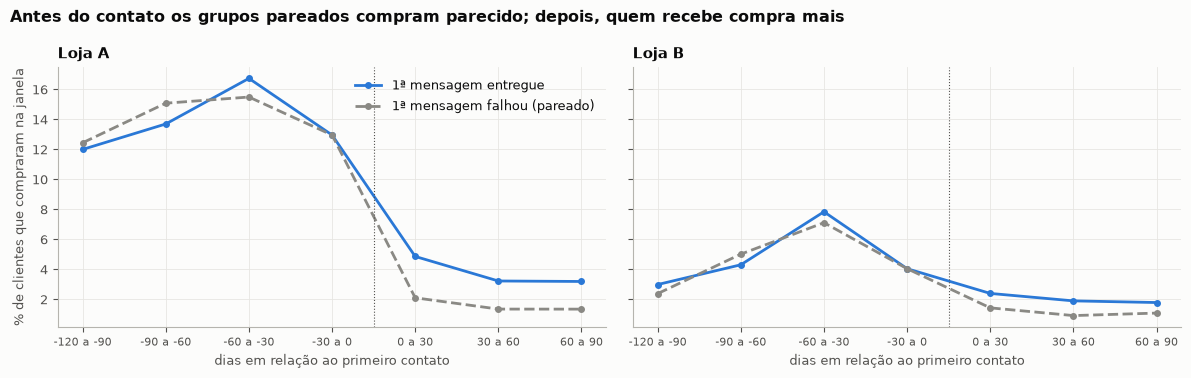

In [16]:
# taxa de compra (pareada) em janelas de 30 dias antes e depois do primeiro contato
jan30 = ['pre120_90', 'pre90_60', 'pre60_30', 'pre30_0', 'pos0_30', 'pos30_60', 'pos60_90']
xlab = ['-120 a -90', '-90 a -60', '-60 a -30', '-30 a 0', '0 a 30', '30 a 60', '60 a 90']
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for a, lj in zip(ax, ['Loja A', 'Loja B']):
    d = prim[(prim.loja == lj) & (prim.seguimento_dias >= 90)]
    vals = np.array([att(d.estrato.to_numpy(), d['T'].to_numpy().astype(float), d[y].to_numpy())[:2] for y in jan30])
    a.plot(range(7), vals[:, 0] * 100, color=AZUL, marker='o', ms=4, label='1ª mensagem entregue')
    a.plot(range(7), vals[:, 1] * 100, color=CINZA, ls='--', marker='o', ms=4, label='1ª mensagem falhou (pareado)')
    a.axvline(3.5, color=TINTA2, lw=0.8, ls=':')
    a.set_xticks(range(7)); a.set_xticklabels(xlab, fontsize=8)
    a.set_title(lj); a.set_xlabel('dias em relação ao primeiro contato')
ax[0].set_ylabel('% de clientes que compraram na janela')
ax[0].legend(loc='upper right')
fig.suptitle('Antes do contato os grupos pareados compram parecido; depois, quem recebe compra mais', x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
fig.savefig(FIG_DIR / 'fig3_primeiro_contato.png', dpi=160)

### 4.3 Para quem a mensagem rende mais?

Mesmo desenho do 4.2, separando pela recência no primeiro contato. Só a Loja A tem clientes "falhou" suficientes em todos os segmentos (a B tem menos de 50 em vários e a C tem 227 no total).

In [17]:
het = []
for lj in ['Loja A', 'Loja B']:
    for seg in prim.seg_rec.cat.categories:
        d = prim[(prim.loja == lj) & (prim.seg_rec == seg)]
        if (1 - d['T']).sum() < 100:
            continue
        for y in ['pos0_7', 'pos0_30', 'pos0_30_r']:
            dd = janela_ok(d, y)
            m1, m0, ef, lo, hi, cob = att_ic(dd, y, B=300)
            het.append((lj, seg, y, m1, m0, ef, lo, hi, int(dd['T'].sum()), int((1 - dd['T']).sum())))
het = pd.DataFrame(het, columns=['loja', 'recência', 'desfecho', 'recebeu', 'falhou', 'efeito', 'IC95 inf', 'IC95 sup', 'n recebeu', 'n falhou'])
piv = het[het.desfecho == 'pos0_30'].set_index(['loja', 'recência'])[['recebeu', 'falhou', 'efeito', 'IC95 inf', 'IC95 sup', 'n falhou']]
piv['% da conversão que é incremental'] = piv.efeito / piv.recebeu
piv.style.format({'recebeu': '{:.2%}', 'falhou': '{:.2%}', 'efeito': '{:+.2%}', 'IC95 inf': '{:+.2%}', 'IC95 sup': '{:+.2%}',
                  'n falhou': '{:,.0f}', '% da conversão que é incremental': '{:.0%}'}).set_caption('Comprou em 30 dias após o 1º contato')

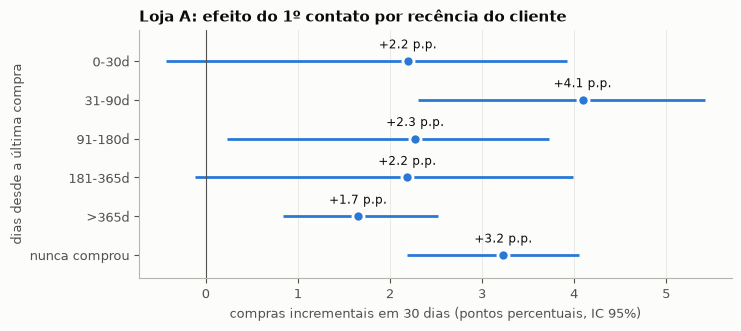

In [18]:
h = het[(het.loja == 'Loja A') & (het.desfecho == 'pos0_30')].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(7.5, 3.4))
yy = np.arange(len(h))[::-1]
ax.hlines(yy, h['IC95 inf'] * 100, h['IC95 sup'] * 100, color=AZUL, lw=2)
ax.plot(h.efeito * 100, yy, 'o', color=AZUL, ms=8, mec='#fcfcfb', mew=2)
for y_, ef in zip(yy, h.efeito):
    ax.annotate(f'{ef * 100:+.1f} p.p.', (ef * 100, y_), xytext=(0, 9), textcoords='offset points', ha='center', fontsize=8.5, color=TINTA)
ax.axvline(0, color=TINTA2, lw=0.8)
ax.set_ylim(-0.6, len(h) - 0.2)
ax.set_yticks(yy); ax.set_yticklabels(h['recência'])
ax.set_xlabel('compras incrementais em 30 dias (pontos percentuais, IC 95%)')
ax.set_ylabel('dias desde a última compra')
ax.set_title('Loja A: efeito do 1º contato por recência do cliente')
ax.grid(axis='y', visible=False)
fig.tight_layout()
fig.savefig(FIG_DIR / 'fig4_recencia.png', dpi=160)

Na Loja A, o maior efeito está em quem comprou há 31-90 dias (+4,1 p.p. em 30 dias; uns 70% da conversão desse grupo é incremental) e em contatos que nunca compraram (+3,2 p.p.). Quem comprou nos últimos 30 dias converte bem, mas o efeito é incerto (o intervalo inclui zero), provavelmente porque muita gente ali compraria de qualquer jeito. Clientes inativos há mais de um ano respondem pouco. Como os intervalos se sobrepõem, trato essa ordem como indicativa; é o tipo de coisa que um holdout por segmento confirmaria. Na Loja B, só "nunca comprou" tem efeito claro (+1,3 p.p.).

### 4.4 A mensagem se paga?

In [19]:
CUSTO_MSG = 0.32   # R$ por mensagem de marketing (tarifa atual da Meta para o Brasil, sem a mensalidade da plataforma)
eco = []
for lj in ['Loja A', 'Loja B']:
    r = res41[res41.loja == lj].set_index('estimativa (7 dias)')
    rec_lb = r.loc[ROT41[2]]
    rec_dd = r.loc[ROT41[3]]
    atr41 = r.loc['referência: receita atribuída / 1.000 msgs, R$'].valor
    r42 = res42[(res42.loja == lj) & (res42.desfecho == 'receita por cliente em 7 dias (R$)')].iloc[0]
    for metodo, v, lo, hi, atr in [('4.1 todas as msgs, vs. linha de base', rec_lb.valor, rec_lb['IC95 inf'], rec_lb['IC95 sup'], atr41),
                                   ('4.1 todas as msgs, dif-em-dif', rec_dd.valor, rec_dd['IC95 inf'], rec_dd['IC95 sup'], atr41),
                                   ('4.2 primeiro contato, pareado', r42.efeito * 1000, r42['IC95 inf'] * 1000, r42['IC95 sup'] * 1000, r42.recebeu * 1000)]:
        eco.append((lj, metodo, atr, v, lo, hi, v / atr, CUSTO_MSG * 1000, CUSTO_MSG * 1000 / v))
eco = pd.DataFrame(eco, columns=['loja', 'método', 'receita "atribuída" / 1.000 msgs (R$)', 'receita incremental / 1.000 msgs (R$, 7d)',
                                 'IC95 inf', 'IC95 sup', '% da atribuída que é incremental', 'custo / 1.000 msgs (R$)', 'margem bruta mínima p/ empatar'])
eco.style.format({c: 'R$ {:,.0f}' for c in eco.columns[2:6]} | {'custo / 1.000 msgs (R$)': 'R$ {:,.0f}', '% da atribuída que é incremental': '{:.0%}',
                                                                'margem bruta mínima p/ empatar': '{:.0%}'}).hide(axis='index')

loja,método,"receita ""atribuída"" / 1.000 msgs (R$)","receita incremental / 1.000 msgs (R$, 7d)",IC95 inf,IC95 sup,% da atribuída que é incremental,custo / 1.000 msgs (R$),margem bruta mínima p/ empatar
Loja A,"4.1 todas as msgs, vs. linha de base","R$ 2,751","R$ 1,031",R$ 889,"R$ 1,183",37%,R$ 320,31%
Loja A,"4.1 todas as msgs, dif-em-dif","R$ 2,751","R$ 1,945","R$ 1,366","R$ 2,650",71%,R$ 320,16%
Loja A,"4.2 primeiro contato, pareado","R$ 2,591","R$ 2,177","R$ 1,804","R$ 2,449",84%,R$ 320,15%
Loja B,"4.1 todas as msgs, vs. linha de base","R$ 5,573","R$ 4,929","R$ 4,492","R$ 5,428",88%,R$ 320,6%
Loja B,"4.1 todas as msgs, dif-em-dif","R$ 5,573","R$ 4,534","R$ 3,767","R$ 5,253",81%,R$ 320,7%
Loja B,"4.2 primeiro contato, pareado","R$ 3,823","R$ 2,047",R$ 448,"R$ 3,715",54%,R$ 320,16%


No cenário mais conservador (Loja A, vs. linha de base), 1.000 mensagens trazem cerca de R$ 1,0 mil de receita incremental em 7 dias para um custo de uns R$ 320. Ou seja, a campanha se paga se a margem bruta for maior que ~31%. Nos outros cenários o ponto de equilíbrio fica entre 6% e 16% de margem. Só algo entre 35% e 90% da receita que a conta simples atribuiria às campanhas é incremental; usar a receita atribuída pode superestimar o retorno em até 2,7 vezes.

A conclusão qualitativa (o canal gera venda incremental e, em média, se paga) aparece nos dois métodos. O valor exato é bem menos firme (ver limitações), e é por isso que a primeira recomendação é medir com holdout.

### 4.5 Limitações

- Não é um experimento. O grupo "falhou" é formado por clientes com número inválido ou sem WhatsApp. Pareei por loja, mês, recência e frequência, e os placebos de 60-120 dias antes do contato ficam perto de zero, mas pode haver diferenças que não observo: um número desatualizado pode indicar um cliente que já estava se afastando da loja, ou um cadastro com telefone falso. Isso infla a estimativa, então leio os números como um teto otimista.
- Identidade do cliente. Não sei como o `customer_id` é gerado. Se depender do telefone, quem troca de número vira "outro cliente" e some do grupo "falhou", o que também infla o efeito.
- Grupo de comparação pequeno: cerca de 3,3 mil clientes na Loja A, 1,7 mil na B e só 227 na C. Na C nada é conclusivo e, na B, os segmentos são frágeis.
- A primeira mensagem não é uma mensagem típica. O efeito do primeiro contato pode ser maior que o da décima (novidade). A estimativa 4.1 usa todas as mensagens, mas a linha de base dela também sofre influência de campanhas anteriores.
- O efeito inclui a oferta. Se a mensagem traz um cupom exclusivo, o que medi é mensagem + desconto, e a receita incremental não desconta o custo do desconto.
- Janela de 7 dias. Ela pega o pico, mas pode haver antecipação de compra. No 4.2, a janela de 90 dias não mostra queda depois, o que sugere que não é só isso.
- As campanhas podem estar truncadas em 5.000 mensagens na extração, e o período da Loja A é curto (nov/2023 a jun/2024).

### 5. Fatores associados à conversão (descritivo)

Aqui comparo campanhas entre si. Cada campanha tem um template, uma mídia e um horário, mas também um público e uma oferta que eu não observo. Por isso essas diferenças são hipóteses para testar, não conclusões.

In [20]:
rec_all = msg[cens & (msg.grupo == 'recebeu')].copy()
rec_all['hora_brt'] = (rec_all.created_at.dt.hour - 3) % 24   # timestamps estão em UTC
cmp = rec_all.groupby(['loja', 'whatsapp_campaign_id']).agg(
    media=('media', 'first'), botao=('has_button', 'first'), cta=('has_cta', 'first'), hora=('hora_brt', 'first'),
    n=('id', 'size'), conv=('conv7', 'mean'), clique=('clicou', 'mean')).reset_index()


def resumo(df, col):
    g = df.groupby(['loja', col])
    out = pd.DataFrame({'campanhas': g.size(), 'mensagens': g.n.sum(),
                        'conv7 (ponderada)': g.apply(lambda x: np.average(x.conv, weights=x.n)),
                        'conv7 (mediana das campanhas)': g.conv.median(),
                        'clique (mediana)': g.clique.median()})
    return out[out.campanhas >= 3]


fmt5 = {'mensagens': '{:,.0f}', 'conv7 (ponderada)': '{:.2%}', 'conv7 (mediana das campanhas)': '{:.2%}', 'clique (mediana)': '{:.1%}'}
resumo(cmp, 'media').style.format(fmt5).set_caption('Tipo de mídia (só a Loja B varia de fato)')

In [21]:
cmp['faixa_hora'] = pd.cut(cmp.hora, [0, 11, 14, 17, 20, 24], right=False, labels=['antes 11h', '11-14h', '14-17h', '17-20h', '20h+'])
resumo(cmp, 'faixa_hora').style.format(fmt5).set_caption('Horário do disparo (horário de Brasília)')

In [22]:
# frequência: quantas mensagens o cliente recebeu nos 30 dias anteriores
rec_all = rec_all.sort_values(['ck', 'created_at'])
tt = epoch(rec_all.created_at)
chave_t = rec_all.ck.to_numpy() * 10**10 + tt
rec_all['msgs_30d'] = np.arange(len(tt)) - np.searchsorted(chave_t, chave_t - 30 * D, 'left')
rec_all['f30'] = np.minimum(rec_all.msgs_30d, 3)
ingenuo = rec_all.groupby(['loja', 'f30']).conv7.mean().unstack(0)

# mesmo cliente em momentos diferentes: efeito fixo de cliente (centrando por cliente) + dummies de mês
e = rec_all[rec_all.groupby('ck').id.transform('size') >= 3]
X = pd.concat([pd.get_dummies(e.f30, prefix='f30', drop_first=True),
               pd.get_dummies(e.created_at.dt.to_period('M').astype(str), prefix='mes', drop_first=True)], axis=1).astype(float)
Xc = X - X.groupby(e.ck.values).transform('mean')
yc = e.conv7.astype(float) - e.groupby('ck').conv7.transform('mean')
beta = np.linalg.lstsq(Xc.to_numpy(), yc.to_numpy(), rcond=None)[0]
fe = pd.Series(beta, index=X.columns)[[c for c in X.columns if c.startswith('f30')]]
freq = ingenuo.copy()
freq.index = ['0', '1', '2', '3+']
freq['efeito fixo de cliente (vs. 0 msgs)'] = [0.0] + list(fe.values)
print(f'base do modelo de efeito fixo: {len(e):,} mensagens de {e.ck.nunique():,} clientes; conversão média {e.conv7.mean():.2%}')
freq.style.format('{:.2%}').set_caption('conv7 por número de mensagens recebidas nos 30 dias anteriores')

base do modelo de efeito fixo: 218,691 mensagens de 33,914 clientes; conversão média 2.37%


loja,Loja A,Loja B,Loja C,efeito fixo de cliente (vs. 0 msgs)
0,1.98%,1.67%,2.28%,0.00%
1,2.48%,1.80%,3.33%,-0.64%
2,2.62%,2.62%,3.81%,-0.89%
3+,3.41%,3.74%,1.75%,-1.63%


Na média simples, quem recebe mais mensagens converte mais, mas isso é seleção: cliente engajado entra em mais públicos. Comparando o mesmo cliente em momentos diferentes, cada mensagem a mais no mês vem com conversão menor por mensagem, ou seja, retorno decrescente. Não é prova (o momento das campanhas também muda), mas é um bom motivo para testar um limite de frequência.

### 6. Modelo baseline de propensão

Objetivo: estimar, no momento do disparo, a chance de o cliente comprar em 7 dias se receber a mensagem. Isso serve para ordenar clientes dentro de um público e para prever o resultado de uma campanha.

Algumas escolhas:
- Base: mensagens recebidas com 7 dias de acompanhamento.
- Features calculadas só com informação anterior ao envio: histórico de compra (recência, pedidos em 30/90/365 dias, valor, ticket médio, tempo de casa), histórico de mensagens (quantas recebeu, quantas nos últimos 30 dias, dias desde a última, cliques e respostas anteriores) e dados da campanha (loja, mídia, botão/CTA, hora, dia da semana, tamanho do disparo).
- Validação temporal: treino até mar/2024, validação em abr-mai/2024 e teste em jun-jul/2024, para simular o uso real (treina no passado, aplica no futuro) e evitar vazamento.
- Métricas: a classe é rara (~2%), então PR-AUC e lift no topo da lista (quanto o top 10%/20% converte acima da média) importam mais que acurácia. ROC-AUC fica como referência.
- Modelos: regressão logística como referência interpretável e gradient boosting (HistGradientBoosting) para pegar não linearidades e interações.

In [23]:
mf = msg.sort_values(['ck', 'created_at']).reset_index(drop=True)
ckf, t0f, tf = mf.ck.to_numpy(), mf.t0.to_numpy(), epoch(mf.created_at)
for dias, nome in [(30, 'ped_30d'), (90, 'ped_90d'), (365, 'ped_365d'), (3650, 'ped_total')]:
    n, r = idx.janela(ckf, t0f - dias * D, t0f)
    mf[nome] = n
    mf[nome + '_rs'] = r
lb, pr = idx.ultimo_antes(ckf, t0f), idx.primeiro(ckf)
mf['recencia'] = np.where(np.isnan(lb), 9999, (t0f - lb) / D)
mf['tempo_casa'] = np.where(np.isnan(pr) | (pr >= t0f), -1, (t0f - pr) / D)
mf['ticket_medio'] = np.where(mf.ped_total > 0, mf.ped_total_rs / np.maximum(mf.ped_total, 1), 0)
mf['msgs_antes'] = mf.groupby('ck').cumcount()
chave_t = ckf * 10**10 + tf
mf['msgs_30d'] = np.arange(len(tf)) - np.searchsorted(chave_t, chave_t - 30 * D, 'left')
mf['dias_desde_ult_msg'] = (mf.created_at - mf.groupby('ck').created_at.shift()).dt.days.fillna(9999)


def eventos_antes(col):
    # conta cliques/respostas do cliente que aconteceram antes do envio atual (pelo horário do evento)
    ev = mf.loc[mf[col].notna(), ['ck', col]]
    k = np.sort(ev.ck.to_numpy() * 10**10 + epoch(ev[col]))
    return np.searchsorted(k, ckf * 10**10 + tf, 'left') - np.searchsorted(k, ckf * 10**10, 'left')


mf['cliques_antes'] = eventos_antes('clicked_at')
mf['respostas_antes'] = eventos_antes('replied_at')
mf['recebidas_antes'] = mf.groupby('ck').grupo.transform(lambda s: (s == 'recebeu').astype(int).cumsum().shift(fill_value=0))
mf['hora_brt'] = (mf.created_at.dt.hour - 3) % 24
mf['dia_semana'] = mf.created_at.dt.dayofweek
mf['tam_campanha'] = mf.groupby('whatsapp_campaign_id').id.transform('size')
mf['loja_cod'] = mf.loja.map({'Loja A': 0, 'Loja B': 1, 'Loja C': 2})
mf['midia_cod'] = mf.media.map({'image': 0, 'texto': 1, 'video': 2, 'file': 3})
mf['botao'] = mf.has_button.astype(int)
mf['cta'] = mf.has_cta.astype(int)
mf['y'] = mf.conv7.astype(int)

FEATS = ['loja_cod', 'recencia', 'tempo_casa', 'ped_30d', 'ped_90d', 'ped_365d', 'ped_total', 'ped_365d_rs', 'ticket_medio',
         'msgs_antes', 'msgs_30d', 'dias_desde_ult_msg', 'cliques_antes', 'respostas_antes', 'recebidas_antes',
         'hora_brt', 'dia_semana', 'tam_campanha', 'midia_cod', 'botao', 'cta']
CATEG = ['loja_cod', 'midia_cod', 'botao', 'cta', 'hora_brt', 'dia_semana']
base6 = mf[(mf.grupo == 'recebeu') & (mf.created_at <= FIM - pd.Timedelta(days=7))]
treino = base6[base6.created_at < '2024-04-01']
valid = base6[(base6.created_at >= '2024-04-01') & (base6.created_at < '2024-06-01')]
teste = base6[base6.created_at >= '2024-06-01']
print({n: (len(d), f'{d.y.mean():.2%}') for n, d in [('treino', treino), ('validação', valid), ('teste', teste)]})

{'treino': (140886, '2.15%'), 'validação': (70778, '2.28%'), 'teste': (56989, '2.02%')}


In [24]:
def X_log(df):
    """Para a logística: log1p nas contagens e valores (cauda longa) e one-hot nas categóricas."""
    num = np.log1p(df[[f for f in FEATS if f not in CATEG]].clip(lower=-1) + 1)
    cat = pd.get_dummies(df[CATEG].astype(str), drop_first=False)
    return pd.concat([num, cat], axis=1)


cols_log = X_log(treino).columns
X_l = lambda df: X_log(df).reindex(columns=cols_log, fill_value=0).astype(float)

logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.5))
logit.fit(X_l(treino), treino.y)

gbm = HistGradientBoostingClassifier(max_iter=500, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=200,
                                     l2_regularization=1.0, categorical_features=[FEATS.index('loja_cod'), FEATS.index('midia_cod')],
                                     early_stopping=True, validation_fraction=0.15, random_state=0)
gbm.fit(treino[FEATS], treino.y)


def lift(y, p, q):
    k = int(len(p) * q)
    return y[np.argsort(-p)[:k]].mean() / y.mean()


avaliacao = []
modelos = {'heurística: menor recência': lambda df: -df.recencia.to_numpy(),
           'regressão logística': lambda df: logit.predict_proba(X_l(df))[:, 1],
           'gradient boosting': lambda df: gbm.predict_proba(df[FEATS])[:, 1]}
for nome, f in modelos.items():
    for conj, df in [('validação', valid), ('teste', teste)]:
        p, y = f(df), df.y.to_numpy()
        avaliacao.append((nome, conj, roc_auc_score(y, p), average_precision_score(y, p), y.mean(), lift(y, p, .1), lift(y, p, .2)))
avaliacao = pd.DataFrame(avaliacao, columns=['modelo', 'conjunto', 'ROC-AUC', 'PR-AUC', 'taxa base', 'lift top 10%', 'lift top 20%'])
avaliacao.style.format({'ROC-AUC': '{:.3f}', 'PR-AUC': '{:.3f}', 'taxa base': '{:.2%}', 'lift top 10%': '{:.2f}x', 'lift top 20%': '{:.2f}x'}).hide(axis='index')

modelo,conjunto,ROC-AUC,PR-AUC,taxa base,lift top 10%,lift top 20%
heurística: menor recência,validação,0.591,0.031,2.28%,1.18x,1.35x
heurística: menor recência,teste,0.573,0.025,2.02%,1.33x,1.44x
regressão logística,validação,0.700,0.066,2.28%,3.15x,2.30x
regressão logística,teste,0.658,0.058,2.02%,2.89x,2.05x
gradient boosting,validação,0.721,0.076,2.28%,3.38x,2.56x
gradient boosting,teste,0.694,0.055,2.02%,2.96x,2.42x


,previsto,observado,mensagens,% das conversões
decil,,,,
1,0.38%,0.89%,"5,699",4%
2,0.58%,1.04%,"5,699",5%
3,0.76%,0.88%,"5,699",4%
4,0.95%,0.84%,"5,699",4%
5,1.21%,1.19%,"5,699",6%
6,1.36%,1.65%,"5,698",8%
7,1.57%,1.65%,"5,699",8%
8,2.02%,2.30%,"5,699",11%
9,3.00%,3.83%,"5,699",19%


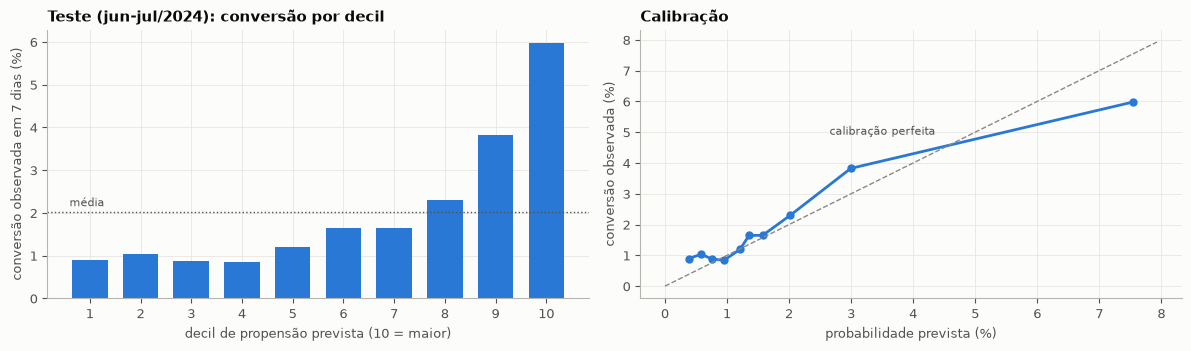

In [25]:
p_teste = gbm.predict_proba(teste[FEATS])[:, 1]
dec = pd.DataFrame({'p': p_teste, 'y': teste.y.to_numpy()})
dec['decil'] = pd.qcut(dec.p.rank(method='first'), 10, labels=range(1, 11))
cal = dec.groupby('decil').agg(previsto=('p', 'mean'), observado=('y', 'mean'), mensagens=('y', 'size'))
cal['% das conversões'] = dec.groupby('decil').y.sum() / dec.y.sum()

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].bar(cal.index.astype(int), cal.observado * 100, color=AZUL, width=0.7)
ax[0].axhline(dec.y.mean() * 100, color=TINTA2, ls=':', lw=1)
ax[0].annotate('média', (0.6, dec.y.mean() * 100), xytext=(0, 4), textcoords='offset points', fontsize=8, color=TINTA2)
ax[0].set_xticks(range(1, 11)); ax[0].set_xlabel('decil de propensão prevista (10 = maior)')
ax[0].set_ylabel('conversão observada em 7 dias (%)'); ax[0].set_title('Teste (jun-jul/2024): conversão por decil')
ax[1].plot(cal.previsto * 100, cal.observado * 100, 'o-', color=AZUL, ms=5)
lim = max(cal.previsto.max(), cal.observado.max()) * 105
ax[1].plot([0, lim], [0, lim], color=CINZA, ls='--', lw=1)
ax[1].annotate('calibração perfeita', (lim * 0.55, lim * 0.62), fontsize=8, color=TINTA2, ha='right')
ax[1].set_xlabel('probabilidade prevista (%)'); ax[1].set_ylabel('conversão observada (%)'); ax[1].set_title('Calibração')
fig.tight_layout()
fig.savefig(FIG_DIR / 'fig5_modelo.png', dpi=160)
cal.style.format({'previsto': '{:.2%}', 'observado': '{:.2%}', 'mensagens': '{:,.0f}', '% das conversões': '{:.0%}'})

In [26]:
imp = permutation_importance(gbm, valid[FEATS], valid.y, scoring='average_precision', n_repeats=5, random_state=0)
importancia = pd.Series(imp.importances_mean, index=FEATS).sort_values(ascending=False)
importancia.head(10).to_frame('queda no PR-AUC ao embaralhar').style.format('{:.4f}')

,queda no PR-AUC ao embaralhar
ped_total,0.0199
recencia,0.0178
ped_365d,0.0160
tam_campanha,0.0151
cliques_antes,0.0119
ticket_medio,0.0038
dias_desde_ult_msg,0.0033
ped_365d_rs,0.0028
hora_brt,0.0023
msgs_antes,0.0020


No teste (jun-jul/2024), o gradient boosting chega a ROC-AUC de 0,69 e lift de uns 3x no top 10%: esse décimo da lista concentra 30% das conversões, contra 1,3x da heurística "quem comprou mais recentemente". A logística fica perto, o que indica que o ganho vem das features de histórico (pedidos, recência, cliques anteriores) e não do algoritmo. O tamanho do disparo também pesa: campanhas pequenas e segmentadas convertem mais que disparos em massa. A calibração é razoável, mas o decil mais alto fica superestimado no teste (7,6% previsto contra 6,0% observado), o que sugere mudança de público no período (jun/2024 teve o maior volume de envios da Loja A). Em produção, o modelo precisaria ser recalibrado de tempos em tempos.

Um cuidado importante: propensão não é incrementalidade. O modelo responde "quem vai comprar se receber", e não "quem compra porque recebeu". Ordenar o público só pela propensão tende a concentrar os envios em quem já compraria. Para virar regra de público, ele precisa ser combinado com o efeito por segmento (seção 4.3) e, idealmente, trocado por um modelo de uplift (T-learner ou X-learner) treinado com dados de holdout, que hoje não existem. Com o grupo "falhou" atual (umas 50 conversões em 7 dias na base inteira), um uplift individual seria só ruído.

### 7. Recomendações

1. Medir com grupo de controle em toda campanha. Reservar por sorteio 5 a 10% de cada público, que não recebe a mensagem, e acompanhar a receita incremental por 1.000 mensagens no lugar da receita atribuída. Isso transforma as estimativas deste notebook (teto otimista, intervalos largos) em medição direta, e ainda vira argumento comercial, porque a plataforma passa a provar o próprio retorno. O tamanho necessário está calculado abaixo.
2. Mudar a prioridade do público. Até o holdout confirmar, priorizar clientes que compraram há 31-90 dias e contatos que nunca compraram, onde o efeito estimado é maior, e reduzir o peso de quem comprou nos últimos 30 dias. Dentro de cada segmento, usar o modelo de propensão para ordenar.
3. Testar um limite de frequência, por exemplo 2 mensagens por cliente a cada 30 dias, medindo a receita incremental total e não por mensagem.
4. Limpar a base de telefones. Cerca de 6,2 mil clientes têm falha de entrega e 82% deles falham sempre. Parar de enviar depois de 2 falhas seguidas (uns 3% dos disparos) e pedir atualização do telefone na compra.
5. Testar conteúdo e horário com A/B. Na Loja B, campanhas só de texto convertem tanto quanto ou mais que imagem e vídeo, mas isso é correlação (público e oferta mudam junto).
6. Melhorar os dados: trazer status, horário e devoluções da Loja C; registrar o código de erro das falhas (número inválido ou limite de frequência da Meta); registrar a regra de público e a oferta de cada campanha; e ligar o cupom usado no pedido à campanha que o enviou.
7. Próximo passo de modelagem: com 2-3 meses de holdout, treinar um modelo de uplift e escolher o público pela receita incremental esperada menos o custo da mensagem.

In [ ]:
# tamanho do holdout: clientes por grupo para detectar uma diferença de conversão em 7 dias
def n_por_grupo(p0, p1, alfa=0.05, poder=0.8):
    z = norm.ppf(1 - alfa / 2) + norm.ppf(poder)
    return int(np.ceil(z**2 * (p0 * (1 - p0) + p1 * (1 - p1)) / (p1 - p0) ** 2))


cenarios = pd.DataFrame([(p0, p1, n_por_grupo(p0, p1)) for p0, p1 in [(0.004, 0.022), (0.010, 0.020), (0.015, 0.020), (0.020, 0.025)]],
                        columns=['conversão sem mensagem', 'conversão com mensagem', 'clientes no holdout'])
cenarios['msgs no grupo que recebe (holdout = 10%)'] = cenarios['clientes no holdout'] * 9
cenarios.style.format({'conversão sem mensagem': '{:.1%}', 'conversão com mensagem': '{:.1%}', 'clientes no holdout': '{:,.0f}',
                       'msgs no grupo que recebe (holdout = 10%)': '{:,.0f}'}).hide(axis='index')

conversão sem mensagem,conversão com mensagem,clientes no holdout,msgs no grupo que recebe (holdout = 10%)
0.4%,2.2%,618,"5,562"
1.0%,2.0%,"2,316","20,844"
1.5%,2.0%,"10,793","97,137"
2.0%,2.5%,"13,807","124,263"


Com o efeito estimado na Loja A (de 0,4% para 2,2%), algumas centenas de clientes no holdout já detectam o efeito médio, o que cabe numa única campanha grande. Para efeitos menores, como diferenças de 0,5 p.p. entre segmentos, o holdout precisa ser acumulado ao longo de vários disparos. Por isso faz mais sentido ele ser padrão no produto do que um teste pontual.